<a href="https://colab.research.google.com/github/ThomasAlbin/Space-Science-With-Python/blob/main/2026/size_from_brightness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# How Big Is 2026 ED138? A Size from Nothing but Brightness

In 2026, the Vera C. Rubin Observatory found **2026 ED138**, its first dwarf planet candidate, about 47 times farther from the Sun than Earth. Even at its largest possible size it would appear only about 0.05 arcseconds across, far too small for any telescope on the ground to see its disc. All we have is a dot, and how bright that dot is. Yet from its brightness alone we can already say a lot about its size. It takes three steps.

**1. The apparent magnitude $m$.** Astronomers measure brightness in magnitudes. The scale goes back to the ancient Greeks, who ranked the brightest stars "first magnitude" and the faintest they could see "sixth magnitude". In 1856, Norman Pogson made it exact: five magnitudes are a factor of 100 in brightness, and higher numbers mean fainter. For a flux $F$ and a reference flux $F_0$:

$$m = -2.5 \log_{10}\left(\frac{F}{F_0}\right)$$

**2. The absolute magnitude $H$.** How bright an object looks depends on how far away it is. Sunlight travels out to it, a distance $r$ from the Sun, and the reflected light travels back to us, a distance $\Delta$. Both legs dilute the light with the square of the distance. The light also depends on the **phase angle** $\alpha$, the angle between the Sun and the observer as seen from the object: at $\alpha = 0$ we see it fully lit, like a full Moon. The absolute magnitude $H$ is the brightness the object would have at $r = \Delta = 1$ au and $\alpha = 0$. For asteroids and other small bodies, the IAU uses the **H–G system** (Bowell et al. 1989):

$$m = H + 5 \log_{10}(r\,\Delta) - 2.5 \log_{10}\big[(1 - G)\,\Phi_1(\alpha) + G\,\Phi_2(\alpha)\big]$$

with $r$ and $\Delta$ in au, the two phase functions $\Phi_i(\alpha) = \exp\left(-A_i \tan^{B_i}(\alpha/2)\right)$ with $A_1 = 3.33$, $B_1 = 0.63$, $A_2 = 1.87$, $B_2 = 1.22$, and the slope parameter $G$. Catalogues like JPL's use $G = 0.15$ when it hasn't been measured. Out at 47 au, the phase angle is never more than about 1.2°, so this last term is small.

**3. From $H$ to the size.** A body's brightness depends on its size and on how much light its surface reflects: its geometric albedo $p$. A small, bright, icy body can look just like a big, dark one. For a diameter $D$:

$$D = \frac{1329\ \text{km}}{\sqrt{p}} \cdot 10^{-H/5}$$

The albedo of 2026 ED138 hasn't been measured yet, so we get a range of sizes. Let's compute it!

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('dark_background')

## Get the Data

**The apparent magnitude.** The Minor Planet Center published Rubin's observations of 2026 ED138 in [MPEC 2026-U85](https://minorplanetcenter.net/mpec/K26/K26U85.html). Rubin measures through its own filters, so we take two colours from neighbouring nights: $g$ = 20.26 and 20.23 on 2026 May 22, and $i$ = 19.36 on May 23. The discovery paper (Holman et al. 2026) converts them to the standard V band with $V = g - 0.302\,(g - i) - 0.041$.

**The geometry.** JPL's [Horizons](https://ssd.jpl.nasa.gov/horizons/) system computes where 2026 ED138 was on that night, seen from the Rubin Observatory (site code `X05`): the distance to the Sun $r$ (`r`), the distance to us $\Delta$ (`delta`) and the phase angle $\alpha$ (`S-T-O`). You can ask for them in the web app, or with [this API query](https://ssd.jpl.nasa.gov/api/horizons.api?format=text&COMMAND=%27DES%3D2026%20ED138%3B%27&OBJ_DATA=NO&MAKE_EPHEM=YES&EPHEM_TYPE=OBSERVER&CENTER=%27X05%27&TLIST=%272026-05-23%2000%3A00%27&QUANTITIES=%279%2C19%2C20%2C24%27), for 2026 May 23, 00:00 UT.

In [2]:
g = (20.26 + 20.23) / 2
i = 19.36

V = g - 0.302 * (g - i) - 0.041
print(f"Apparent magnitude: V = {V:.2f}")

Apparent magnitude: V = 19.94


In [3]:
r, delta, alpha = 47.186, 46.372, 0.742  # au, au, degrees (JPL Horizons)

## The Phase Function

The H–G phase function tells us how much fainter the object looks at a phase angle $\alpha$ than fully lit. At $\alpha = 0$ it's exactly 0 magnitudes.

In [4]:
def hg_phase(alpha, G=0.15):
    """How much fainter (in magnitudes) a body looks at the phase angle alpha (degrees) than at zero phase."""
    t = np.tan(np.radians(alpha) / 2)
    phi1, phi2 = np.exp(-3.33 * t**0.63), np.exp(-1.87 * t**1.22)
    return -2.5 * np.log10((1 - G) * phi1 + G * phi2)

## The Absolute Magnitude

Now we undo the distance and the phase angle: $H = m - 5 \log_{10}(r\,\Delta) + 2.5 \log_{10}\big[(1 - G)\,\Phi_1 + G\,\Phi_2\big]$.

In [5]:
distance = 5 * np.log10(r * delta)

H = V - distance - hg_phase(alpha)
print(f"Distance: {distance:.2f} mag, phase angle: {hg_phase(alpha):.2f} mag, H = {H:.2f}")

Distance: 16.70 mag, phase angle: 0.13 mag, H = 3.11


## From Brightness to Size

The same brightness for three different surfaces: as dark as fresh asphalt ($p$ = 0.04), a typical large trans-Neptunian object ($p$ = 0.10) and a brighter, icier surface ($p$ = 0.25).

In [6]:
def diameter_km(H, albedo):
    """Diameter (km) of a body with the absolute magnitude H and the geometric albedo."""
    return 1329 / np.sqrt(albedo) * 10**(-H / 5)


for p in [0.04, 0.10, 0.25]:
    print(f"Albedo {p:.2f}: D = {diameter_km(H, p):,.0f} km")

Albedo 0.04: D = 1,588 km
Albedo 0.10: D = 1,004 km
Albedo 0.25: D = 635 km


## Visualisation

The diameter for every albedo from very dark to very bright. The shaded band marks the albedos the discovery team thinks are most likely, and the dashed line is Pluto for comparison.

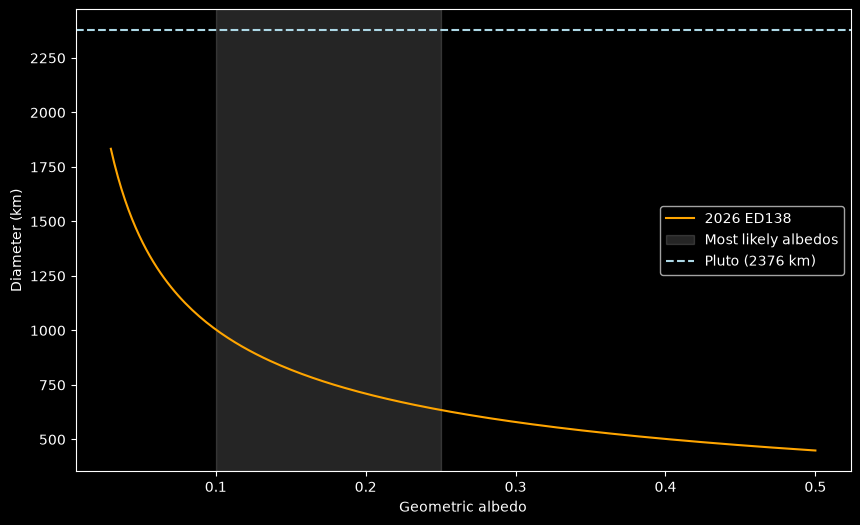

In [7]:
albedos = np.linspace(0.03, 0.5, 200)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(albedos, diameter_km(H, albedos), color='orange', label="2026 ED138")
ax.axvspan(0.10, 0.25, color='white', alpha=0.15, label="Most likely albedos")
ax.axhline(2376, color='lightblue', ls='--', label="Pluto (2376 km)")
ax.set_xlabel("Geometric albedo")
ax.set_ylabel("Diameter (km)")
ax.legend()
plt.show()

## Take-Aways

* **The distance does almost everything:** the factor $5 \log_{10}(r\,\Delta)$ makes 2026 ED138 almost 17 magnitudes fainter, about five million times, than it would be at 1 au from the Sun and from us. The phase angle adds only about 0.1 magnitudes.
* **Our $H$ is about 3.1.** The discovery team gets $H_V = 3.19 \pm 0.04$ from all of Rubin's and the Dark Energy Camera's observations, with a straight-line phase law ($H + \beta\alpha$, $\beta$ = 0.14 mag/deg) instead of H–G. That shifts our sizes by about 4 %. In the video we use their value: 600 to 1,500 km.
* **The catalogues disagree:** JPL lists $H$ = 2.85 and predicts $V$ = 19.68 for that night, but Rubin's $g$ and $i$ give 19.94. The catalogues combine observations from several filters with standard colour corrections, and 2026 ED138 is redder than the average asteroid. A brighter $H$ means a bigger object: with JPL's $H$, the sizes would be about 13 % larger than ours.
* **The albedo is the big unknown:** between $p$ = 0.04 and 0.25, the diameter changes by a factor of 2.5. The discovery team favours the brighter half, because large trans-Neptunian objects tend to be brighter. Thermal infrared measurements or a stellar occultation will settle it.
* **Even at its biggest, it's smaller than Pluto,** and less than half the Moon's 3,475 km.
* **Try it yourself:** change $G$ to 0.05 or 0.30 and see how little it matters at such small phase angles. Or use JPL's $H$ = 2.85 instead of ours.

## Sources

* Holman, Jurić, Napier et al. (2026): 2026 ED138: A Large Trans-Neptunian Object in Early Rubin Observatory Data, and How Many More May Remain. Submitted to AJ. https://arxiv.org/abs/2610.38693
* Minor Planet Center (2026): MPEC 2026-U85, 2026 ED138. https://minorplanetcenter.net/mpec/K26/K26U85.html
* JPL Horizons System, 2026 ED138, orbit solution JPL#2. https://ssd.jpl.nasa.gov/horizons/
* Bowell, Hapke, Domingue et al. (1989): Application of photometric models to asteroids. In: Asteroids II, University of Arizona Press, 524–556.
* Harris & Harris (1997): On the Revision of Radiometric Albedos and Diameters of Asteroids. Icarus 126, 450–454. https://doi.org/10.1006/icar.1996.5664
* Pravec & Harris (2007): Binary asteroid population 1. Angular momentum content. Icarus 190, 250–259. https://doi.org/10.1016/j.icarus.2007.02.023
* Pogson (1856): Magnitudes of Thirty-six of the Minor Planets for the First Day of each Month of the Year 1857. MNRAS 17, 12–15. https://doi.org/10.1093/mnras/17.1.12
* NASA NSSDC: Pluto Fact Sheet. https://nssdc.gsfc.nasa.gov/planetary/factsheet/plutofact.html